# VOTING CLASSIFIER ALGORITHEM

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('heart_risk.csv')

df.head()


,Age,Gender,BMI,Smoking_Status,COVID_Severity,SpO2,Blood_Pressure,Heart_Rate,ECG_Result,Troponin_Level,D_Dimer,CRP,Blood_Sugar,Cholesterol_Level,Hypertension,Diabetes,Vaccine_Given,Heart_Risk
0,69,Male,29.0,Yes,Severe,92.9,127,121,Abnormal,59.77,1.23,75.53,247,155,No,Yes,Yes,High Risk
1,32,Male,18.3,Yes,Severe,96.3,168,62,Abnormal,94.83,4.30,52.56,190,266,No,No,Yes,Medium Risk
2,89,Female,37.9,No,Moderate,89.2,121,87,Normal,28.25,1.76,120.99,180,176,Yes,No,Yes,High Risk
3,78,Male,19.0,No,Moderate,85.8,141,85,Normal,24.74,4.45,156.48,235,226,Yes,No,Yes,High Risk
4,38,Female,25.1,Yes,Moderate,92.3,90,86,Abnormal,2.64,1.70,21.93,227,158,Yes,No,Yes,Low Risk


In [3]:
df=df.dropna()

In [4]:
df.columns

Index(['Age', 'Gender', 'BMI', 'Smoking_Status', 'COVID_Severity', 'SpO2',
       'Blood_Pressure', 'Heart_Rate', 'ECG_Result', 'Troponin_Level',
       'D_Dimer', 'CRP', 'Blood_Sugar', 'Cholesterol_Level', 'Hypertension',
       'Diabetes', 'Vaccine_Given', 'Heart_Risk'],
      dtype='object')

In [5]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

var = ['Gender','Smoking_Status','COVID_Severity','ECG_Result','Hypertension','Diabetes','Heart_Risk','Vaccine_Given']
  
for i in var:
    df[i] = le.fit_transform(df[i]).astype(int)

In [6]:
df.head()

,Age,Gender,BMI,Smoking_Status,COVID_Severity,SpO2,Blood_Pressure,Heart_Rate,ECG_Result,Troponin_Level,D_Dimer,CRP,Blood_Sugar,Cholesterol_Level,Hypertension,Diabetes,Vaccine_Given,Heart_Risk
0,69,1,29.0,1,2,92.9,127,121,0,59.77,1.23,75.53,247,155,0,1,1,0
1,32,1,18.3,1,2,96.3,168,62,0,94.83,4.30,52.56,190,266,0,0,1,2
2,89,0,37.9,0,1,89.2,121,87,1,28.25,1.76,120.99,180,176,1,0,1,0
3,78,1,19.0,0,1,85.8,141,85,1,24.74,4.45,156.48,235,226,1,0,1,0
4,38,0,25.1,1,1,92.3,90,86,0,2.64,1.70,21.93,227,158,1,0,1,1


In [7]:
x1 = df.drop(labels='Heart_Risk', axis=1)
y1 = df.loc[:,'Heart_Risk']

In [8]:
import imblearn
from imblearn.over_sampling import RandomOverSampler
from collections import Counter

ros =RandomOverSampler(random_state=42)
x,y=ros.fit_resample(x1,y1)
print("OUR DATASET COUNT         : ", Counter(y1))
print("OVER SAMPLING DATA COUNT  : ", Counter(y))

OUR DATASET COUNT         :  Counter({2: 5617, 0: 3413, 1: 970})
OVER SAMPLING DATA COUNT  :  Counter({0: 5617, 2: 5617, 1: 5617})


In [9]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=42, stratify=y)
print("NUMBER OF TRAIN DATASET    : ", len(x_train))
print("NUMBER OF TEST DATASET      : ", len(x_test))
print("TOTAL NUMBER OF DATASET    : ", len(x_train)+len(x_test))

NUMBER OF TRAIN DATASET    :  13480
NUMBER OF TEST DATASET      :  3371
TOTAL NUMBER OF DATASET    :  16851


In [10]:
print("NUMBER OF TRAIN DATASET    : ", len(y_train))
print("NUMBER OF TEST DATASET      : ", len(y_test))
print("TOTAL NUMBER OF DATASET    : ", len(y_train)+len(y_test))

NUMBER OF TRAIN DATASET    :  13480
NUMBER OF TEST DATASET      :  3371
TOTAL NUMBER OF DATASET    :  16851


In [11]:
from sklearn.ensemble import VotingClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# Base models
dt = DecisionTreeClassifier(max_depth=5, random_state=42)
xgb = XGBClassifier(max_depth=3, n_estimators=100, learning_rate=0.1, random_state=42)

# Voting classifier (hard voting)
VCF = VotingClassifier(estimators=[('dt', dt), ('xgb', xgb)], voting='hard')

# Fit
VCF.fit(x_train, y_train)


VotingClassifier(estimators=[('dt',
                              DecisionTreeClassifier(max_depth=5,
                                                     random_state=42)),
                             ('xgb',
                              XGBClassifier(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            colsample_bytree=None, device=None,
                                            early_stopping_rounds=None,
                                            enable_categorical=False,
                                            eval_metric=None,
                                            feature_types=None, gamma=None,
                                            grow_policy=None,
                                            importance_type=None,
                                            interaction_constraints=None,
                                            learning_rate=0.1, max_bin=None,
                                            max_cat_threshold=None,
                                            max_cat_to_onehot=None,
                                            max_delta_step=None, max_depth=3,
                                            max_leaves=None,
                                            min_child_weight=None, missing=nan,
                                            monotone_constraints=None,
                                            multi_strategy=None,
                                            n_estimators=100, n_jobs=None,
                                            num_parallel_tree=None,
                                            random_state=42, ...))])

In [12]:
predicted = VCF.predict(x_test)

In [13]:
from sklearn.metrics import classification_report
cr = classification_report(y_test,predicted)
print('THE CLASSIFICATION REPORT OF VOTING CLASSIFIER:\n\n',cr)

THE CLASSIFICATION REPORT OF VOTING CLASSIFIER:

               precision    recall  f1-score   support

           0       0.84      1.00      0.91      1123
           1       0.87      1.00      0.93      1124
           2       1.00      0.66      0.79      1124

    accuracy                           0.89      3371
   macro avg       0.90      0.89      0.88      3371
weighted avg       0.90      0.89      0.88      3371



In [14]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test,predicted)
print('THE CONFUSION MATRIX SCORE OF VOTING CLASSIFIER:\n\n\n',cm)

THE CONFUSION MATRIX SCORE OF VOTING CLASSIFIER:


 [[1123    0    0]
 [   0 1124    0]
 [ 212  173  739]]


In [15]:
from sklearn.model_selection import cross_val_score
accuracy = cross_val_score(VCF, x, y, scoring='accuracy')
print('THE CROSS VALIDATION TEST RESULT OF ACCURACY :\n\n\n', accuracy*100)

THE CROSS VALIDATION TEST RESULT OF ACCURACY :


 [87.86710175 86.29080119 87.21068249 89.43620178 89.55489614]


In [16]:
from sklearn.metrics import accuracy_score
a = accuracy_score(y_test,predicted)
print("THE ACCURACY SCORE OF VOTING CLASSIFIER IS :",a*100)

THE ACCURACY SCORE OF VOTING CLASSIFIER IS : 88.57905665974488


In [17]:
from sklearn.metrics import hamming_loss
hl = hamming_loss(y_test,predicted)
print("THE HAMMING LOSS OF VOTING CLASSIFIER IS :",hl*100)

THE HAMMING LOSS OF VOTING CLASSIFIER IS : 11.420943340255118


THE CONFUSION MATRIX SCORE OF VOTING CLASSIFIER:


[[1123    0    0]
 [   0 1124    0]
 [ 212  173  739]]


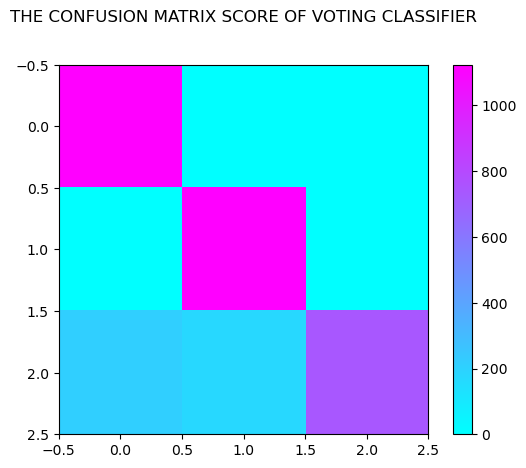

In [18]:
def plot_confusion_matrix(cm, title='THE CONFUSION MATRIX SCORE OF VOTING CLASSIFIER\n\n', cmap=plt.cm.cool):
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()

cm1=confusion_matrix(y_test, predicted)
print('THE CONFUSION MATRIX SCORE OF VOTING CLASSIFIER:\n\n')
print(cm)
plot_confusion_matrix(cm)

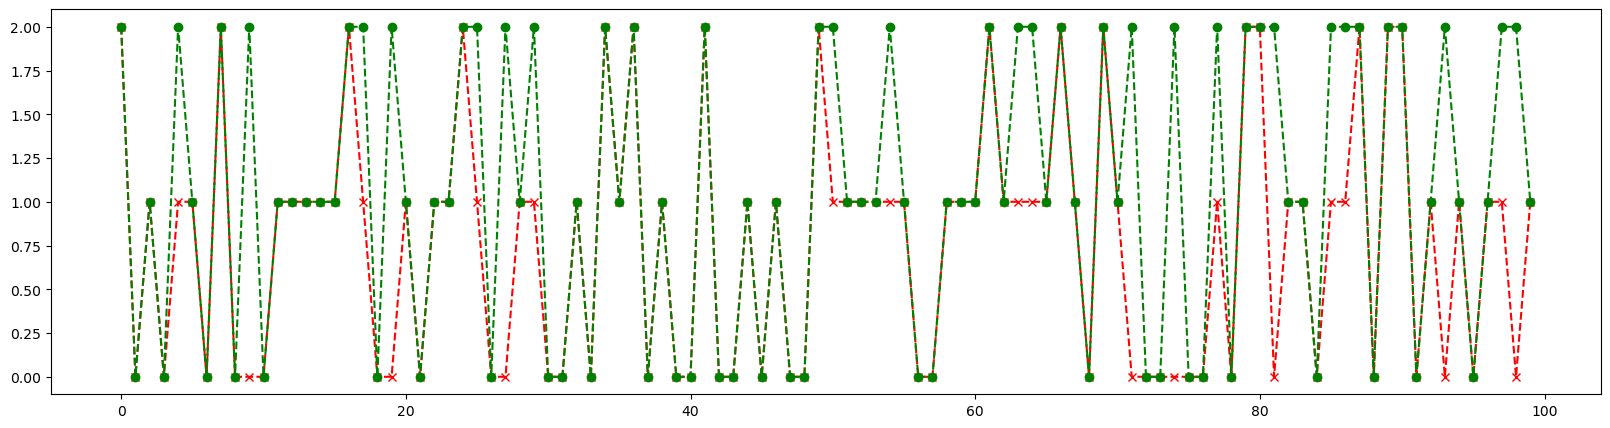

In [19]:
import matplotlib.pyplot as plt
df2 = pd.DataFrame()
df2["y_test"] = y_test
df2["predicted"] = predicted
df2.reset_index(inplace=True)
plt.figure(figsize=(20, 5))
plt.plot(df2["predicted"][:100], marker='x', linestyle='dashed', color='red')
plt.plot(df2["y_test"][:100],  marker='o', linestyle='dashed', color='green')
plt.show()

In [20]:
import joblib
joblib.dump(VCF, 'heart.pkl')

['heart.pkl']